# 23. Variational Principles for Eigenvalues
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

Courant–Fischer for $A=\mathrm{diag}(3,2,1)$. Each plane through the origin is represented by its unit normal $\nu$, drawn in the upper hemisphere seen from above (the centre is $\nu=e_3$, the rim contains $e_1$ and $e_2$). Left: the largest value of the Rayleigh quotient on the plane $\nu^{\perp}$. It never drops below $\lambda_2=2$, and equals $2$ exactly on the red arcs: the planes that contain $e_2$ and lie inside the cone $x_1^2\le x_3^2$. Right: the smallest value on the plane; it never exceeds $2$, with equality on the complementary red arc. The eigenvalue $\lambda_2$ is a saddle value, the minimum of maxima and the maximum of minima.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


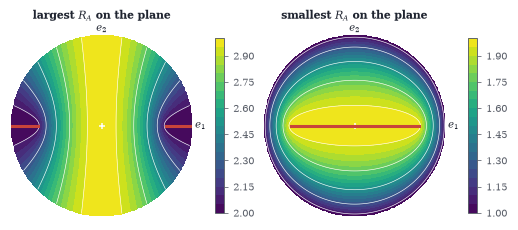

In [2]:
Ad = np.diag([3.0, 2.0, 1.0]); g = np.linspace(-1, 1, 241); X, Y = np.meshgrid(g, g); Z2 = 1 - X**2 - Y**2
fmax = np.full(X.shape, np.nan); fmin = np.full(X.shape, np.nan)
for i in range(len(g)):
    for j in range(len(g)):
        if Z2[i, j] < 0: continue
        nu = np.array([X[i, j], Y[i, j], np.sqrt(Z2[i, j])]); Qn, _ = np.linalg.qr(np.c_[nu, np.eye(3)])
        ev = np.linalg.eigvalsh(Qn[:, 1:3].T @ Ad @ Qn[:, 1:3]); fmin[i, j], fmax[i, j] = ev
fig, axs = plt.subplots(1, 2, figsize=(W, 2.15))
for ax, F, ttl, lv in [(axs[0], fmax, "largest $R_A$ on the plane", [2.05, 2.25, 2.5, 2.75, 2.95]), (axs[1], fmin, "smallest $R_A$ on the plane", [1.05, 1.25, 1.5, 1.75, 1.95])]:
    im = ax.contourf(X, Y, F, 20, cmap="viridis"); ax.contour(X, Y, F, lv, colors="white", linewidths=0.4)
    ax.set_aspect("equal"); ax.axis("off"); ax.set_title(ttl, fontsize=7, pad=10); fig.colorbar(im, ax=ax, shrink=0.8)
    ax.text(1.03, 0, "$e_1$", fontsize=6.5, va="center"); ax.text(0, 1.04, "$e_2$", fontsize=6.5, ha="center"); ax.plot(0, 0, "+", color="white", ms=4)
r2 = 1 / np.sqrt(2); axs[0].plot([r2, 1], [0, 0], color=RED, lw=2); axs[0].plot([-1, -r2], [0, 0], color=RED, lw=2); axs[1].plot([-r2, r2], [0, 0], color=RED, lw=2)

Eigenvalues of $A+tE$ for a diagonal $A$ and a random symmetric $E$ with $\lVert E\rVert=1$, as $t$ goes from $0$ to $1.5$. Each eigenvalue stays inside the grey wedge $\lambda_k(A)\pm t$ predicted by Weyl's inequality. The curves never cross: where two of them approach (circled), they swerve apart, an *avoided crossing*.

(0.0, 1.5)

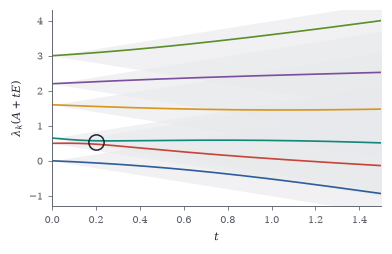

In [3]:
rng = np.random.default_rng(4); n = 6; A0 = np.diag([0.0, 0.5, 0.65, 1.6, 2.2, 3.0])
E0 = rng.normal(size=(n, n)); E0 = (E0 + E0.T) / 2; E0 /= np.linalg.norm(E0, 2)
ts = np.linspace(0, 1.5, 300); L = np.array([np.linalg.eigvalsh(A0 + t * E0) for t in ts])
fig, ax = plt.subplots(figsize=(W * 0.75, 2.2))
for k in range(n):
    ax.fill_between(ts, A0[k, k] - ts, A0[k, k] + ts, color=LIGHT, alpha=0.6, lw=0); ax.plot(ts, L[:, k], color=PALETTE[k], lw=1.1)
gaps = np.diff(L, axis=1)[40:]; tt, kk = np.unravel_index(np.argmin(gaps), gaps.shape); tt += 40
ax.plot(ts[tt], (L[tt, kk] + L[tt, kk + 1]) / 2, "o", ms=10, mfc="none", color=INK, lw=0.6)
ax.set_xlabel("$t$"); ax.set_ylabel(r"$\lambda_k(A+tE)$"); ax.set_ylim(-1.3, 4.3); ax.set_xlim(0, 1.5)

A Gelfand–Tsetlin pattern. Row $k$ shows the eigenvalues of the leading $k\times k$ principal submatrix of a random $7\times7$ symmetric matrix. Each row interlaces the row above it (grey zigzags join each eigenvalue to the two that bound it from the next row). The spread of the eigenvalues grows with $k$, the extreme ones moving monotonically outwards.

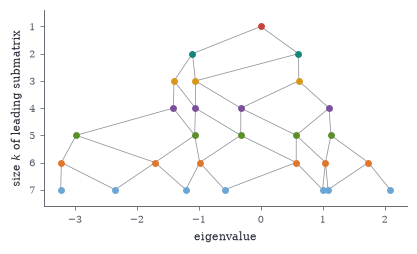

In [4]:
rng = np.random.default_rng(7); n = 7; G = rng.normal(size=(n, n)); G = (G + G.T) / 2
rows = [np.sort(np.linalg.eigvalsh(G[:k, :k]))[::-1] for k in range(1, n + 1)]
fig, ax = plt.subplots(figsize=(W * 0.8, 2.2))
for k in range(1, n):
    for j, m in enumerate(rows[k - 1]):
        ax.plot([rows[k][j], m, rows[k][j + 1]], [k + 1, k, k + 1], color=GRAY, lw=0.5)
for k, r in enumerate(rows, start=1): ax.plot(r, np.full(k, k), "o", color=PALETTE[k % 10], ms=3.5, zorder=3)
ax.set_ylim(n + 0.6, 0.4); ax.set_ylabel("size $k$ of leading submatrix"); ax.set_xlabel("eigenvalue"); ax.set_yticks(range(1, n + 1))

The secular function $f(\lambda)=1+\rho\sum_j z_j^2/(d_j-\lambda)$ for $d=(1,2,3.5,4,6)$ and a random $z$, with $\rho=1$. Between consecutive poles (dashed) $f$ rises from $-\infty$ to $+\infty$, so it crosses zero exactly once (red dots, the eigenvalues of $D+\rho zz^{\mathsf T}$); one more root lies to the right of the largest pole. The roots interlace the poles, as the rank-one theorem requires.

Text(0, 0.5, '$f(\\lambda)$')

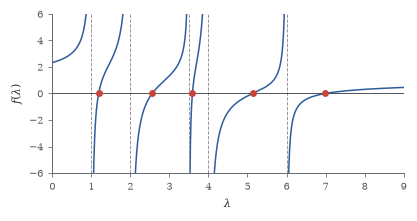

In [5]:
d = np.array([1, 2, 3.5, 4, 6.0]); z = np.random.default_rng(1).uniform(0.4, 1, 5); rho = 1.0
f = lambda t: 1 + rho * np.sum(z[:, None]**2 / (d[:, None] - t[None, :]), axis=0)
roots = np.linalg.eigvalsh(np.diag(d) + rho * np.outer(z, z))
fig, ax = plt.subplots(figsize=(W * 0.8, 1.9))
edges = np.r_[0, np.sort(d), 9.0]
for lo, hi in zip(edges[:-1], edges[1:]):
    t = np.linspace(lo + 1e-3, hi - 1e-3, 400); ax.plot(t, f(t), color=BLUE, lw=1)
for dj in d: ax.axvline(dj, color=GRAY, ls="--", lw=0.6)
ax.axhline(0, color=INK, lw=0.5); ax.plot(roots, 0 * roots, "o", color=RED, ms=3.5, zorder=4)
ax.set_ylim(-6, 6); ax.set_xlim(0, 9); ax.set_xlabel(r"$\lambda$"); ax.set_ylabel(r"$f(\lambda)$")

Horn's problem for $3\times3$ matrices. With $\lambda(A)=(4,1,0)$ and $\lambda(B)=(3,2,0)$ fixed, the spectrum of $A+QBQ^{\mathsf T}$ for $8000$ random rotations $Q$ (blue), drawn in the plane of trace $10$, together with the spectra of the commuting cases $A+PBP^{\mathsf T}$ for permutations $P$. The possible spectra fill a convex polygon (outlined: the convex hull of all these points), cut out by the Horn inequalities. The red point $\lambda^\downarrow(A)+\lambda^\downarrow(B)=(7,3,0)$ is the most spread spectrum allowed (Ky Fan); the gold point, $\lambda^\downarrow(A)+\lambda^\uparrow(B)=(4,3,3)$, is the least spread.

(np.float64(-0.17677669529663687),
 np.float64(3.7123106012293743),
 np.float64(0.22453655975512465),
 np.float64(4.266194635347369))

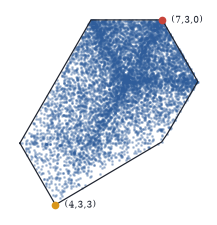

In [6]:
from scipy.spatial import ConvexHull
from itertools import permutations
a = np.array([4, 1, 0.]); b = np.array([3, 2, 0.]); rng = np.random.default_rng(8); S = []
for _ in range(8000):
    Q, R = np.linalg.qr(rng.normal(size=(3, 3))); Q *= np.sign(np.diag(R)); S.append(np.sort(np.linalg.eigvalsh(np.diag(a) + Q @ np.diag(b) @ Q.T))[::-1])
S += [np.sort(a + np.array(p))[::-1] for p in permutations(b)]          # commuting cases: the vertices
S = np.array(S); e1 = np.array([1, -1, 0]) / np.sqrt(2); e2 = np.array([1, 1, -2]) / np.sqrt(6); pr = lambda v: np.c_[v @ e1, v @ e2]
P2 = pr(S); hl = ConvexHull(P2)
fig, ax = plt.subplots(figsize=(W * 0.55, W * 0.42))
ax.scatter(*P2.T, s=0.8, color=BLUE, alpha=0.3); ax.plot(*np.r_[P2[hl.vertices], P2[hl.vertices[:1]]].T, color=INK, lw=0.8)
for v, c, lab, dx in [((7, 3, 0), RED, "(7,3,0)", 0.18), ((4, 3, 3), GOLD, "(4,3,3)", 0.18)]:
    q = pr(np.array(v, float)[None])[0]; ax.plot(*q, "o", color=c, ms=4, zorder=4); ax.text(q[0] + dx, q[1], lab, fontsize=6, va="center")
ax.set_aspect("equal"); ax.axis("off")

In [7]:
d = np.arange(1, 7.0); zz = np.ones(6) / np.sqrt(6); rho = 2.0
sec = lambda t: 1 + rho * np.sum(zz**2 / (d - t))
def bisect(lo, hi, it=100):
    for _ in range(it):
        mid = (lo + hi) / 2
        if sec(mid) < 0: lo = mid
        else: hi = mid
    return (lo + hi) / 2
brackets = list(zip(d, np.r_[d[1:], d[-1] + rho * zz @ zz]))
rts = np.array([bisect(lo + 1e-12, hi - 1e-12) for lo, hi in brackets])
M = np.diag(d) + rho * np.outer(zz, zz)
print("secular roots:", np.round(rts, 10)); print("eigvalsh:     ", np.round(np.linalg.eigvalsh(M), 10))
v = zz / (d - rts[2]); v /= np.linalg.norm(v); print("residual of (D - lambda I)^{-1} z:", np.linalg.norm(M @ v - rts[2] * v))

secular roots: [1.17887355 2.21569043 3.24874928 4.28807948 5.35117298 6.71743427]
eigvalsh:      [1.17887355 2.21569043 3.24874928 4.28807948 5.35117298 6.71743427]
residual of (D - lambda I)^{-1} z: 1.824282583346435e-15


In [8]:
from itertools import combinations
rng = np.random.default_rng(11); n = 6
Xa = rng.normal(size=(n, n)); Aa = Xa + Xa.T; Xb = rng.normal(size=(n, n)); Bb = (Xb + Xb.T) / 3
la, lb, lab = [np.sort(np.linalg.eigvalsh(M))[::-1] for M in (Aa, Bb, Aa + Bb)]
worst = (np.inf, None)
for k in range(1, n + 1):
    for I in combinations(range(n), k):
        slack = la[list(I)].sum() + lb[:k].sum() - lab[list(I)].sum()
        assert slack > -1e-10
        if k < n: worst = min(worst, (slack, I))
print("all 63 Lidskii inequalities hold; among proper index sets the smallest slack is %.4f, at %s" % (worst[0], tuple(i + 1 for i in worst[1])))

all 63 Lidskii inequalities hold; among proper index sets the smallest slack is 0.4934, at (4,)


In [9]:
lam4 = np.array([5, 3, 2, 0.]); mu3 = np.array([4, 2.5, 1.])
bsq = np.array([-np.prod(m - lam4) / np.prod([m - q for q in mu3 if q != m]) for m in mu3])
a_corner = lam4.sum() - mu3.sum(); Arw = np.zeros((4, 4)); Arw[:3, :3] = np.diag(mu3); Arw[:3, 3] = Arw[3, :3] = np.sqrt(bsq); Arw[3, 3] = a_corner
print("b_j^2 =", np.round(bsq, 4), "  corner a =", a_corner)
print("eigenvalues:", np.round(np.sort(np.linalg.eigvalsh(Arw))[::-1], 10), "  submatrix:", np.round(np.sort(np.linalg.eigvalsh(Arw[:3, :3]))[::-1], 10))

b_j^2 = [1.7778 0.6944 1.7778]   corner a = 2.5
eigenvalues: [ 5.  3.  2. -0.]   submatrix: [4.  2.5 1. ]
